# Fine-tuning YOLO11x-OBB — (1) **Semua layer** (full fine-tuning)

Seluruh parameter (backbone/encoder, neck, dan head OBB) dilatih mulai dari bobot **`WARAJA/Tzefa-Line-Segmentation-YOLO`** (`best.pt`) — model YOLO11x-OBB yang **sudah dilatih untuk segmentasi baris tulisan** (satu kelas, `names = {0: 'line'}`).
Karena titik awalnya sudah paham tugas ini, konfigurasi dirancang sebagai **fine-tuning (penyesuaian domain)**, bukan pelatihan dari nol: menyamai resolusi model asal, dengan langkah belajar yang lebih halus dan augmentasi yang lebih ringan.

| Hyperparameter | Nilai | Dasar |
|---|---|---|
| Resolusi (`imgsz`) | **640** | Disamakan dengan model asal (input di-letterbox ke 640) |
| Kelas | 1 (`line`) | Disamakan dengan model asal; head **tidak** diinisialisasi ulang |
| Optimizer | SGD + momentum Nesterov (0,937) | Spesifikasi awal |
| Learning rate awal (`lr0`) | **0,002** | Lebih kecil dari 0,01 agar fitur yang sudah terlatih tidak rusak |
| Learning rate akhir (`lrf`) | 0,1 × lr0 = 0,0002 | Linear decay (`cos_lr=False`) |
| Warmup | **1 epoch**, `warmup_bias_lr=0,01` | Bias lama (0,1) terlalu agresif untuk model terlatih |
| Weight decay | 0,0005 | Spesifikasi awal |
| Batch / `nbs` | **4 / 16** | ±4 iterasi per update (batch efektif 16), jauh lebih banyak update daripada `batch=2, nbs=64` |
| Epochs | 30 | Spesifikasi awal (tanpa early stopping) |
| Augmentasi | mosaic & mixup **mati**, rotasi ±2°, skala ±25%, HSV ringan, tanpa flip | Halaman manuskrip punya tata letak tetap; flip merusak arah baca |

**Catatan**
- Nilai pada kolom "Dasar" yang menyebut model asal (resolusi 640, satu kelas) berasal dari model card; nilai lr, warmup, batch, dan augmentasi adalah **rancangan fine-tuning** yang masuk akal sebagai titik awal, bukan hasil tuning. Jika Anda membandingkan dengan notebook fine-tuning lain (mis. freeze encoder), pakai nilai yang **sama** di semua notebook agar perbandingannya adil.
- `optimizer="SGD"` pada Ultralytics selalu dibuat dengan `nesterov=True`. Linear decay: `lr(e) = lr0 · [(1 − e/E)(1 − lrf) + lrf]`.
- Ultralytics mengakumulasi gradien `round(nbs/batch)` iterasi per update; sel "Estimasi jumlah update" di bawah mencetak total update optimizer pada konfigurasi ini.
- Nama kelas harus `line`. Label hanya menyimpan id `0`; namanya diambil dari `data.yaml` (sel data di bawah memaksanya menjadi `{0: 'line'}`).
- **Syarat:** dataset hasil konversi (`images/`, `labels/`, `data.yaml`) tersedia di sesi ini, GPU aktif, dan Internet ON (untuk mengunduh bobot).

In [1]:
!pip install -q shapely lxml tqdm huggingface_hub

In [2]:
HF_REPO_ID = "WARAJA/Tzefa-Line-Segmentation-YOLO"
HF_FILENAME = "best.pt"
WORK_DIR = "/kaggle/working"

In [3]:
from huggingface_hub import hf_hub_download

model_path = hf_hub_download(repo_id=HF_REPO_ID, filename=HF_FILENAME, local_dir=f"{WORK_DIR}/yolov11-obb-base")
print("Model tersimpan di:", model_path)
# (Warning "unauthenticated requests to the HF Hub" aman diabaikan.)

best.pt: reconstructing file:   0%|          |  0.00B /  118MB            

best.pt: downloading bytes:           |  0.00B            

Model tersimpan di: /kaggle/working/yolov11-obb-base/best.pt


In [4]:
# Ultralytics (di Kaggle biasanya sudah ada; sel ini hanya memastikan)
import importlib, subprocess, sys
try:
    importlib.import_module("ultralytics")
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])

import os, re, json
from pathlib import Path
os.environ["WANDB_DISABLED"] = "true"          # matikan logger eksternal

import yaml, torch
import pandas as pd
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__, "| torch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK ADA (aktifkan GPU di Kaggle: Settings > Accelerator)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.218 | torch: 2.11.0+cu130
GPU: Tesla T4


In [5]:
# ------------------------------ KONFIGURASI ------------------------------
RUN_NAME      = "ft_all"
PROJECT       = "/kaggle/working/runs"
DATA_YAML_SRC = None                 # None = cari otomatis; SEBAIKNYA isi path dataset yang SAMA dengan notebook evaluasi, mis.
                                     # "/kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2/data.yaml"
IMGSZ         = 640                  # = resolusi model asal (letterbox 640); jangan dinaikkan agar domain input tetap sama
DEVICE        = 0 if torch.cuda.is_available() else "cpu"   # 1 GPU; hindari DDP agar callback freeze aman
WORKERS       = 2
CLASS_NAME    = "line"               # = names model asal

# Konfigurasi FINE-TUNING (titik awal sudah terlatih untuk baris tulisan -> langkah belajar halus, augmentasi ringan)
TRAIN_ARGS = dict(
    epochs=30,
    batch=4,
    nbs=16,                   # batch efektif 16 -> ±4 iterasi per update (lihat sel estimasi update)
    optimizer="SGD",          # Ultralytics memakai SGD(momentum, nesterov=True) -> Nesterov aktif
    momentum=0.937,
    lr0=0.002,                # lebih kecil dari default 0.01: jangan merusak fitur yang sudah terlatih
    lrf=0.1,                  # lr akhir = lr0 * lrf = 0.0002
    cos_lr=False,             # False = linear decay
    weight_decay=0.0005,
    warmup_epochs=1,
    warmup_bias_lr=0.01,      # default 0.1 terlalu agresif untuk bobot terlatih
    warmup_momentum=0.8,
    imgsz=IMGSZ,
    device=DEVICE,
    workers=WORKERS,
    patience=30,              # = epochs -> tanpa early stopping
    seed=42, deterministic=True,
    # Augmentasi ringan: halaman manuskrip punya tata letak tetap (baris horizontal, sedikit miring)
    mosaic=0.0, mixup=0.0,    # mosaic memotong-tempel halaman -> merusak konteks tata letak
    degrees=2.0, translate=0.05, scale=0.25, shear=0.0, perspective=0.0,
    hsv_h=0.01, hsv_s=0.4, hsv_v=0.3,
    fliplr=0.0, flipud=0.0,   # jangan membalik arah baca dokumen
    plots=True, save_period=5,
    project=PROJECT, name=RUN_NAME, exist_ok=False,
)
for k, v in TRAIN_ARGS.items():
    print(f"{k:>14}: {v}")

        epochs: 30
         batch: 4
           nbs: 16
     optimizer: SGD
      momentum: 0.937
           lr0: 0.002
           lrf: 0.1
        cos_lr: False
  weight_decay: 0.0005
 warmup_epochs: 1
warmup_bias_lr: 0.01
warmup_momentum: 0.8
         imgsz: 640
        device: 0
       workers: 2
      patience: 30
          seed: 42
 deterministic: True
        mosaic: 0.0
         mixup: 0.0
       degrees: 2.0
     translate: 0.05
         scale: 0.25
         shear: 0.0
   perspective: 0.0
         hsv_h: 0.01
         hsv_s: 0.4
         hsv_v: 0.3
        fliplr: 0.0
        flipud: 0.0
         plots: True
   save_period: 5
       project: /kaggle/working/runs
          name: ft_all
      exist_ok: False


In [6]:
def find_data_yaml():
    """Cari data.yaml hasil konversi (di /kaggle/working atau dataset yang di-attach sebagai input)."""
    for base in (Path("/kaggle/working"), Path("/kaggle/input")):
        if base.exists():
            for p in sorted(base.rglob("data.yaml")):
                if (p.parent / "images").is_dir() and (p.parent / "labels").is_dir():
                    return p
    return None

src = Path(DATA_YAML_SRC) if DATA_YAML_SRC else find_data_yaml()
assert src is not None and src.exists(), "data.yaml tidak ditemukan. Set DATA_YAML_SRC secara manual."

# Tulis ulang data.yaml dengan 'path' absolut yang benar untuk sesi ini (input Kaggle itu read-only,
# sehingga YAML runtime ditulis ke /kaggle/working).
cfg = yaml.safe_load(src.read_text())
_names = {int(k): v for k, v in (cfg.get("names") or {}).items()}
if _names != {0: CLASS_NAME}:                         # label hanya berisi id 0; samakan nama dengan model asal
    print(f"[!] names di data.yaml sumber = {_names} -> dipaksa menjadi {{0: '{CLASS_NAME}'}}")
    cfg["names"] = {0: CLASS_NAME}
print("Dataset training:", src.parent)
cfg["path"] = str(src.parent.resolve())
for s in ("train", "val", "test"):
    d = src.parent / "images" / s
    if s in cfg and not (d.is_dir() and any(d.iterdir())):
        cfg.pop(s)                                   # buang split yang kosong
DATA_YAML = Path("/kaggle/working/data_runtime.yaml")
DATA_YAML.write_text(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))
print(DATA_YAML.read_text())

for s in ("train", "val", "test"):
    im, lb = src.parent / "images" / s, src.parent / "labels" / s
    if im.is_dir():
        print(f"{s:>5}: {sum(1 for _ in im.iterdir())} gambar, {len(list(lb.glob('*.txt')))} label")

Dataset training: /kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2
path: /kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2
train: images/train
val: images/val
test: images/test
names:
  0: line

train: 206 gambar, 206 label
  val: 25 gambar, 25 label
 test: 27 gambar, 27 label


In [7]:
import math
n_train = sum(1 for p in (src.parent / "images" / "train").iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp", ".webp"})
b, nbs, E = TRAIN_ARGS["batch"], TRAIN_ARGS["nbs"], TRAIN_ARGS["epochs"]
accum = max(round(nbs / b), 1)
iters = math.ceil(n_train / b)
print(f"gambar train      : {n_train}")
print(f"iterasi / epoch   : {iters}  (batch={b})")
print(f"akumulasi         : {accum} iterasi per update  (batch efektif {b * accum})")
print(f"update / epoch    : ~{iters / accum:.1f}")
print(f"total update      : ~{E * iters / accum:.0f}  ({E} epoch)")
if E * iters / accum < 300:
    print("[!] Total update masih sedikit; pertimbangkan menurunkan nbs (mis. nbs=8) atau menambah epoch.")

gambar train      : 206
iterasi / epoch   : 52  (batch=4)
akumulasi         : 4 iterasi per update  (batch efektif 16)
update / epoch    : ~13.0
total update      : ~390  (30 epoch)


In [8]:
# Laporan parameter per bagian arsitektur YOLO11-OBB:
#   backbone/encoder = layer 0-10 | neck = layer 11-22 | head OBB = layer terakhir (23)
BACKBONE_END = 10

def layer_idx(name):
    m = re.match(r"model\.(\d+)\.", name)
    return int(m.group(1)) if m else None

def param_report(trainer):
    net = trainer.model
    head_idx = len(net.model) - 1
    groups = {"backbone (0-10)": [0, 0], "neck (11-22)": [0, 0], f"head OBB ({head_idx})": [0, 0]}
    for n, p in net.named_parameters():
        i = layer_idx(n)
        g = "backbone (0-10)" if i <= BACKBONE_END else ("neck (11-22)" if i < head_idx else f"head OBB ({head_idx})")
        groups[g][0] += p.numel()
        groups[g][1] += p.numel() if p.requires_grad else 0
    print(f"{'bagian':<18}{'total':>14}{'trainable':>14}{'%':>8}")
    for g, (tot, tr) in groups.items():
        print(f"{g:<18}{tot:>14,}{tr:>14,}{100*tr/max(tot,1):>8.1f}")
    T = sum(v[0] for v in groups.values()); R = sum(v[1] for v in groups.values())
    print(f"{'TOTAL':<18}{T:>14,}{R:>14,}{100*R/T:>8.1f}")

## Training

In [9]:
model = YOLO(model_path)
model.add_callback("on_train_start", param_report)     # tampilkan jumlah parameter trainable (harus 100%, kecuali DFL tetap beku)

results = model.train(data=str(DATA_YAML), **TRAIN_ARGS)
SAVE_DIR = Path(model.trainer.save_dir)
print("Hasil tersimpan di:", SAVE_DIR)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_runtime.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/yolov11-obb-base/best.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=ft_all, nbs=16, nms=None, 

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      4.69G      1.234     0.7491      1.496   0.001256         46        640: 100% ━━━━━━━━━━━━ 52/52 3.5it/s 14.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 8.8it/s 0.8s
                   all         25        488      0.962      0.992       0.99      0.663

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss angle_loss  Instances       Size
       3/30      4.69G      1.087     0.6312      1.203   0.001116         38        640: 100% ━━━━━━━━━━━━ 52/52 3.4it/s 15.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 8.2it/s 0.9s
                   all         25        488       0.97       0.99      0.993      0.728

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss angle_loss  Instances       Size
       4/30      4.69G     0.9892     0.5655      1.128  0.0008804         39        640: 100% ━━━━━━━━━━━━ 52/52 3.2it/s 16.0s
        

## Verifikasi jadwal LR & kurva validasi

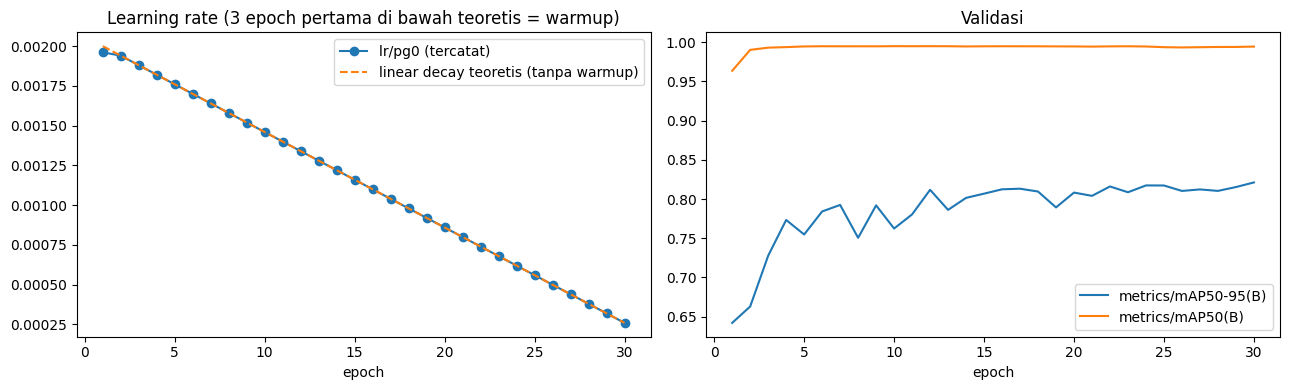

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,train/angle_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,val/angle_loss,lr/pg0,lr/pg1,lr/pg2
25,26,475.892,0.81262,0.41852,0.99269,0.00063,0.99770,0.99795,0.99334,0.81034,0.72165,0.36704,0.96682,0.00028,0.00050,0.00050,0.00050
26,27,494.199,0.78434,0.40978,0.98904,0.00050,0.99776,0.99795,0.99363,0.81226,0.71845,0.36709,0.96156,0.00028,0.00044,0.00044,0.00044
27,28,512.340,0.78582,0.41020,0.99063,0.00053,0.99772,0.99795,0.99393,0.81039,0.71743,0.36177,0.96206,0.00028,0.00038,0.00038,0.00038
28,29,530.415,0.77090,0.40084,0.98273,0.00047,0.99772,0.99795,0.99395,0.81527,0.71581,0.36655,0.96292,0.00030,0.00032,0.00032,0.00032
29,30,548.525,0.77419,0.40471,0.98984,0.00049,0.99770,0.99795,0.99445,0.82117,0.70656,0.36099,0.95821,0.00028,0.00026,0.00026,0.00026


In [10]:
# Verifikasi jadwal learning rate & kurva metrik dari results.csv
res = pd.read_csv(SAVE_DIR / "results.csv"); res.columns = [c.strip() for c in res.columns]
E, lr0, lrf = TRAIN_ARGS["epochs"], TRAIN_ARGS["lr0"], TRAIN_ARGS["lrf"]
expected = [lr0 * ((1 - e / E) * (1 - lrf) + lrf) for e in range(len(res))]    # linear decay lr0 -> lr0*lrf

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(res["epoch"], res["lr/pg0"], "o-", label="lr/pg0 (tercatat)")
ax[0].plot(res["epoch"], expected, "--", label="linear decay teoretis (tanpa warmup)")
ax[0].set_title("Learning rate (3 epoch pertama di bawah teoretis = warmup)"); ax[0].set_xlabel("epoch"); ax[0].legend()
m_cols = [c for c in res.columns if "mAP50-95" in c] + [c for c in res.columns if c.endswith("mAP50(B)")]
for c in m_cols: ax[1].plot(res["epoch"], res[c], label=c)
ax[1].set_title("Validasi"); ax[1].set_xlabel("epoch"); ax[1].legend(); plt.tight_layout(); plt.show()
display(res.tail(5))

## Evaluasi bobot terbaik

In [11]:
# Evaluasi bobot terbaik pada split val dan test (jika ada)
best_path = SAVE_DIR / "weights" / "best.pt"
best = YOLO(str(best_path))
summary = {}
for split in [s for s in ("val", "test") if s in cfg]:
    m = best.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=TRAIN_ARGS["batch"], device=DEVICE,
                 plots=True, name=f"{RUN_NAME}_eval_{split}", exist_ok=True, project=PROJECT)
    summary[split] = {k: round(float(v), 4) for k, v in m.results_dict.items()}
display(pd.DataFrame(summary))
Path(f"/kaggle/working/{RUN_NAME}_metrics.json").write_text(json.dumps(summary, indent=2))
print("Bobot terbaik:", best_path)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11x-obb summary (fused): 199 layers, 58,736,758 parameters, 0 gradients, 203.1 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 1629.9±714.3 MB/s, size: 1786.8 KB)
val: Scanning /kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2/labels/val... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 75.4it/s 0.3s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.2it/s 3.2s
                   all         25        488      0.998      0.998      0.994      0.822
Speed: 1.7ms preprocess, 92.1ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /kaggle/working/runs/ft_all_eval_val
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:

,val,test
metrics/precision(B),0.9977,0.9995
metrics/recall(B),0.9980,0.9981
metrics/mAP50(B),0.9944,0.9950
metrics/mAP50-95(B),0.8216,0.8240
fitness,0.8216,0.8240


Bobot terbaik: /kaggle/working/runs/ft_all/weights/best.pt
